In [6]:
# Import the libraries used in the programs
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.feature import graycomatrix, graycoprops
from sklearn.cluster import KMeans
from skimage.metrics import structural_similarity as ssim
import heapq
from collections import Counter
import math
import os 

## Problem 1: Comparative Edge Detection on Natural Images

#### Download any outdoor natural image (trees, buildings, roads).Apply Sobel, Laplacian, and Canny edge detection.

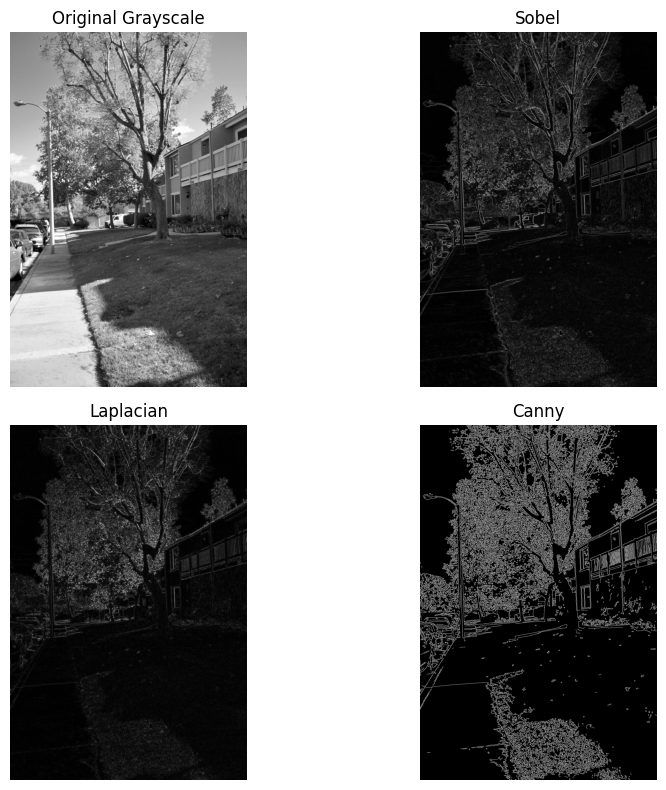

In [7]:
# Read the image and convert it to grayscale
img = cv2.imread('outdoor.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Apply Sobel edge detection in x and y directions
sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
sobel = cv2.magnitude(sobel_x, sobel_y)

# Apply Laplacian and Canny edge detection
# Apply Laplacian edge detection
laplacian = cv2.Laplacian(gray, cv2.CV_64F)

# Convert the result to an 8-bit image for display
laplacian = cv2.convertScaleAbs(laplacian)
canny = cv2.Canny(gray, 100, 200)

# Display the results
plt.figure(figsize=(10, 8))
images = [gray, sobel, laplacian, canny]
titles = ['Original Grayscale', 'Sobel', 'Laplacian', 'Canny']
for i in range(4):
    plt.subplot(2, 2, i + 1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')
plt.tight_layout()
plt.show()



#### Compare the outputs and write a short analysis explaining which operator captures the most meaningful edges and why.

In [8]:
print("Comparison and Analysis of Edge Detection Operators")
print("Sobel: Detects edges by calculating intensity changes in the horizontal and vertical directions. It highlights important boundaries, such as the tree branches, building edges, and sidewalk.")
print("Laplacian: Detects edges using second-order intensity changes. It captures fine details but can also respond to noise, making some edges less clear.")
print("Canny: Produces thin, well-defined edges and highlights boundaries of the tree, building, and road. However, it also detects some less important details in the image.")
print("Conclusion: In this output, Canny captures the most meaningful edges because it produces clearer and more defined boundaries than Sobel and Laplacian. Sobel is useful for understanding gradient direction, while Laplacian highlights fine intensity changes but may produce noisier results.")

Comparison and Analysis of Edge Detection Operators
Sobel: Detects edges by calculating intensity changes in the horizontal and vertical directions. It highlights important boundaries, such as the tree branches, building edges, and sidewalk.
Laplacian: Detects edges using second-order intensity changes. It captures fine details but can also respond to noise, making some edges less clear.
Canny: Produces thin, well-defined edges and highlights boundaries of the tree, building, and road. However, it also detects some less important details in the image.
Conclusion: In this output, Canny captures the most meaningful edges because it produces clearer and more defined boundaries than Sobel and Laplacian. Sobel is useful for understanding gradient direction, while Laplacian highlights fine intensity changes but may produce noisier results.


## Problem 2: Noise Sensitivity Experiment

#### Take a clean grayscale image and intentionally add Gaussian noise and salt-and-pepper noise. Apply Sobel and Laplacian on both noisy versions

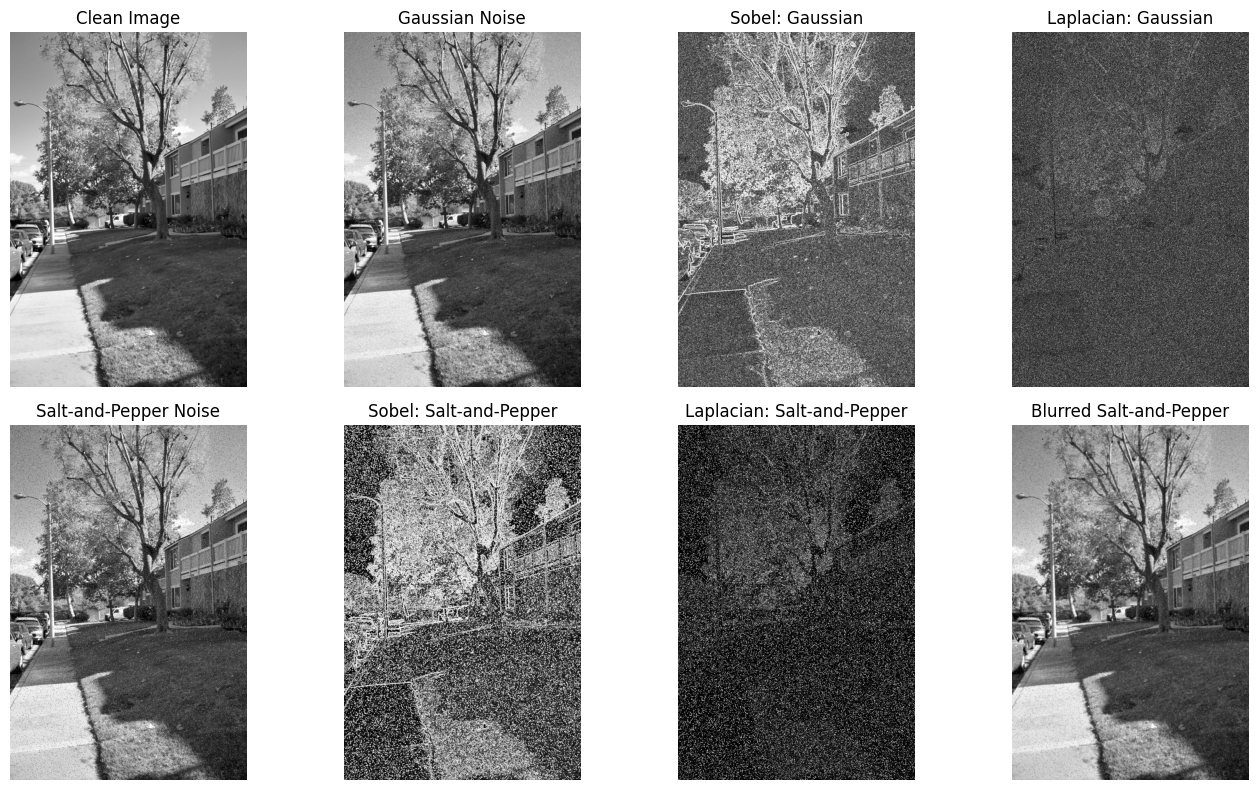

In [9]:
# Add salt-and-pepper noise to the image
noisy_sp = gray.copy()
prob = 0.05  # 5% of pixels will be affected

rand = np.random.rand(*gray.shape)
noisy_sp[rand < prob / 2] = 0        # pepper (black pixels)
noisy_sp[rand > 1 - prob / 2] = 255  # salt (white pixels)
# Apply Sobel on Gaussian-noisy image in x and y directions
# Add Gaussian noise to the image
gaussian_noise = np.random.normal(0, 20, gray.shape)

noisy_gaussian = np.clip(
    gray.astype(np.float32) + gaussian_noise, 0, 255
).astype(np.uint8)

gaussian_sobel_x = cv2.Sobel(
    noisy_gaussian, cv2.CV_64F, 1, 0, ksize=3
)
gaussian_sobel_y = cv2.Sobel(
    noisy_gaussian, cv2.CV_64F, 0, 1, ksize=3
)

# Combine Sobel x and y results
gaussian_sobel = cv2.magnitude(
    gaussian_sobel_x, gaussian_sobel_y
)
gaussian_sobel = cv2.convertScaleAbs(gaussian_sobel)

# Apply Laplacian on Gaussian-noisy image
gaussian_laplacian = cv2.Laplacian(
    noisy_gaussian, cv2.CV_64F
)
gaussian_laplacian = cv2.convertScaleAbs(gaussian_laplacian)

# Apply Sobel on salt-and-pepper noisy image
sp_sobel_x = cv2.Sobel(noisy_sp, cv2.CV_64F, 1, 0, ksize=3)
sp_sobel_y = cv2.Sobel(noisy_sp, cv2.CV_64F, 0, 1, ksize=3)

sp_sobel = cv2.magnitude(sp_sobel_x, sp_sobel_y)
sp_sobel = cv2.convertScaleAbs(sp_sobel)

# Apply Laplacian on salt-and-pepper noisy image
sp_laplacian = cv2.Laplacian(noisy_sp, cv2.CV_64F)
sp_laplacian = cv2.convertScaleAbs(sp_laplacian)

# Apply Gaussian blur before edge detection
blurred_sp = cv2.GaussianBlur(noisy_sp, (5, 5), 0)

plt.figure(figsize=(14, 8))

results = [
    gray, noisy_gaussian, gaussian_sobel, gaussian_laplacian,
    noisy_sp, sp_sobel, sp_laplacian, blurred_sp
]

titles = [
    'Clean Image', 'Gaussian Noise',
    'Sobel: Gaussian', 'Laplacian: Gaussian',
    'Salt-and-Pepper Noise', 'Sobel: Salt-and-Pepper',
    'Laplacian: Salt-and-Pepper', 'Blurred Salt-and-Pepper'
]

for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(results[i], cmap='gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()


#### After apply Sobel and Laplacian on both noisy versions and evaluate:
#### 1. Which operator is more affected by noise?
#### 2. How does edge clarity change?
#### 3. What preprocessing step improves the results?


In [10]:
print("1. Laplacian is more affected by noise because it uses second-order derivatives.")
print("2. Noise creates unwanted edges and reduces edge clarity.")
print("3. Gaussian Blur helps reduce noise and improve edge detection results.")

1. Laplacian is more affected by noise because it uses second-order derivatives.
2. Noise creates unwanted edges and reduces edge clarity.
3. Gaussian Blur helps reduce noise and improve edge detection results.


## Problem 3: Compression Ratio Comparison (RLE vs Huffman)

#### Load a grayscale image with large smooth regions (e.g., document scan or sky image). Compress it using Run-Length Encoding and Huffman Coding separately. Calculate and compare:
#### Bit-length before compression
#### Bit-length after compression
#### Percentage reduction

In [11]:
# Load grayscale image and convert pixels to a 1D list
gray = cv2.imread('smooth_image.jpg', cv2.IMREAD_GRAYSCALE)
pixels = gray.flatten().tolist()

# Run-Length Encoding: store each pixel value and its run count
rle = []
count = 1
for i in range(1, len(pixels)):
    if pixels[i] == pixels[i - 1]:
        count += 1
    else:
        rle.append((pixels[i - 1], count))
        count = 1
rle.append((pixels[-1], count))

# Estimate RLE size: 8 bits for pixel value + 32 bits for run count
original_bits = len(pixels) * 8
rle_bits = len(rle) * (8 + 32)

# Huffman coding: build frequency table
frequencies = Counter(pixels)
heap = [[frequency, [value, '']] for value, frequency in frequencies.items()]
heapq.heapify(heap)

# Build the Huffman tree and assign codes
if len(heap) == 1:
    huffman_codes = {heap[0][1][0]: '0'}
else:
    while len(heap) > 1:
        left = heapq.heappop(heap)
        right = heapq.heappop(heap)
        for item in left[1:]:
            item[1] = '0' + item[1]
        for item in right[1:]:
            item[1] = '1' + item[1]
        heapq.heappush(heap, [left[0] + right[0]] + left[1:] + right[1:])
    huffman_codes = {value: code for value, code in heap[0][1:]}

huffman_bits = sum(frequencies[value] * len(code) for value, code in huffman_codes.items())

# Calculate percentage reduction
rle_reduction = (1 - rle_bits / original_bits) * 100
huffman_reduction = (1 - huffman_bits / original_bits) * 100

print('Original size (bits):', original_bits)
print('RLE encoded size (estimated bits):', rle_bits)
print('RLE percentage reduction: {:.2f}%'.format(rle_reduction))
print('Huffman encoded size (bits):', huffman_bits)
print('Huffman percentage reduction: {:.2f}%'.format(huffman_reduction))


Original size (bits): 13107200
RLE encoded size (estimated bits): 51464800
RLE percentage reduction: -292.65%
Huffman encoded size (bits): 12235786
Huffman percentage reduction: 6.65%


#### Explain why each technique performed the way it did.


In [12]:
print("\nObservation:")
print("- RLE works best when consecutive pixels have the same value.")
print("- Huffman coding works well when some pixel values occur more frequently.")
print("- Compression performance depends on the image's pixel distribution.")


Observation:
- RLE works best when consecutive pixels have the same value.
- Huffman coding works well when some pixel values occur more frequently.
- Compression performance depends on the image's pixel distribution.


## Problem 4: JPEG Block Artifact Analysis

#### Implement an 8×8 block-based JPEG-style compression (DCT + quantisation).
Compress the same image using low, medium, and high quantisation levels.

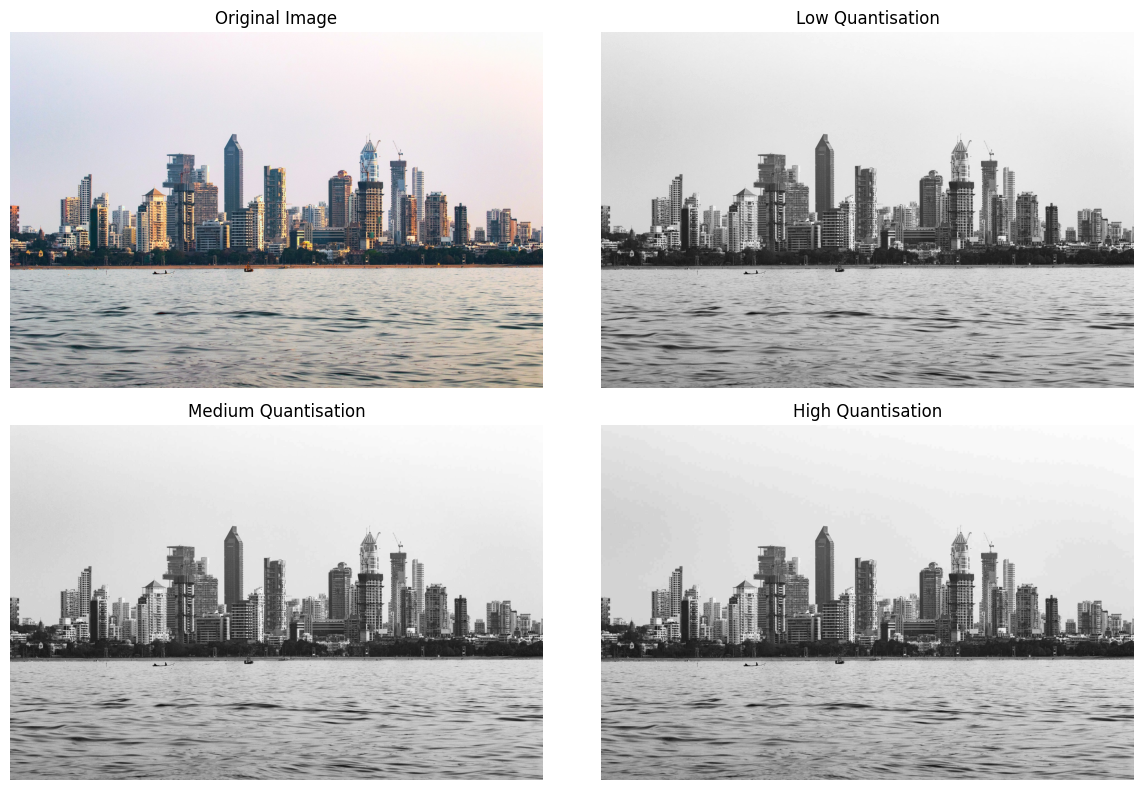

Low Quantisation
MSE: 25.8
PSNR: 34.02 dB
SSIM: 0.9031

Medium Quantisation
MSE: 37.1
PSNR: 32.44 dB
SSIM: 0.8832

High Quantisation
MSE: 55.92
PSNR: 30.65 dB
SSIM: 0.858



In [13]:
# Load colour image and convert BGR to YCrCb
img = cv2.imread('city.jpg')
ycrcb = cv2.cvtColor(img, cv2.COLOR_BGR2YCrCb)
Y = ycrcb[:, :, 0].astype(np.float32)

# JPEG quantisation matrix
Q = np.array([
    [16, 11, 10, 16, 24, 40, 51, 61],
    [12, 12, 14, 19, 26, 58, 60, 55],
    [14, 13, 16, 24, 40, 57, 69, 56],
    [14, 17, 22, 29, 51, 87, 80, 62],
    [18, 22, 37, 56, 68, 109, 103, 77],
    [24, 35, 55, 64, 81, 104, 113, 92],
    [49, 64, 78, 87, 103, 121, 120, 101],
    [72, 92, 95, 98, 112, 100, 103, 99]
], dtype=np.float32)

# Function for 8x8 DCT, quantisation and inverse DCT
def jpeg_compress(image, strength):
    h, w = image.shape

    # Pad image dimensions to multiples of 8
    pad_h = (8 - h % 8) % 8
    pad_w = (8 - w % 8) % 8
    padded = cv2.copyMakeBorder(
        image, 0, pad_h, 0, pad_w, cv2.BORDER_REFLECT
    )

    reconstructed = np.zeros_like(padded)
    quant_matrix = Q * strength

    # Process each 8x8 block
    for y in range(0, padded.shape[0], 8):
        for x in range(0, padded.shape[1], 8):
            block = padded[y:y+8, x:x+8] - 128

            # Apply DCT and quantisation
            dct_block = cv2.dct(block)
            quantized = np.round(dct_block / quant_matrix)

            # Apply inverse quantisation and inverse DCT
            restored_dct = quantized * quant_matrix
            restored = cv2.idct(restored_dct) + 128
            reconstructed[y:y+8, x:x+8] = restored

    return np.clip(reconstructed[:h, :w], 0, 255).astype(np.uint8)


# Compress using low, medium and high quantisation
original = Y.astype(np.uint8)
low = jpeg_compress(Y, 0.5)
medium = jpeg_compress(Y, 1.0)
high = jpeg_compress(Y, 2.0)

# Display original and reconstructed images
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(low, cmap='gray')
plt.title('Low Quantisation')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(medium, cmap='gray')
plt.title('Medium Quantisation')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(high, cmap='gray')
plt.title('High Quantisation')
plt.axis('off')

plt.tight_layout()
plt.show()

# Calculate MSE, PSNR and SSIM
for title, compressed in [
    ('Low', low), ('Medium', medium), ('High', high)
]:
    mse = np.mean((original.astype(float) - compressed.astype(float)) ** 2)
    psnr = 10 * np.log10(255 ** 2 / mse) if mse != 0 else float('inf')
    similarity = ssim(original, compressed, data_range=255)

    print(title, 'Quantisation')
    print('MSE:', round(mse, 2))
    print('PSNR:', round(psnr, 2), 'dB')
    print('SSIM:', round(similarity, 4))
    print()


#### Analyse:
#### Where block artifacts appear
#### Why some textures lose detail
#### How PSNR and SSIM change at each level


In [14]:
print("Analysis:")
print("1. Block artifacts may appear around building edges and in water textures.")
print("2. Fine textures lose detail because quantisation removes high-frequency information.")
print("3. PSNR decreases from 34.02 dB to 30.65 dB, while SSIM decreases from 0.9031 to 0.858 as quantisation increases from low to high.")

Analysis:
1. Block artifacts may appear around building edges and in water textures.
2. Fine textures lose detail because quantisation removes high-frequency information.
3. PSNR decreases from 34.02 dB to 30.65 dB, while SSIM decreases from 0.9031 to 0.858 as quantisation increases from low to high.


## Problem 5: Texture-Based Segmentation using GLCM Features

#### Load a synthetic or natural image that contains multiple textures (wood, fabric, leaves, tiles). 
#### Extract GLCM features (contrast, energy, homogeneity) for each pixel neighbourhood.
#### Segment the image into k = 3 clusters using these features.

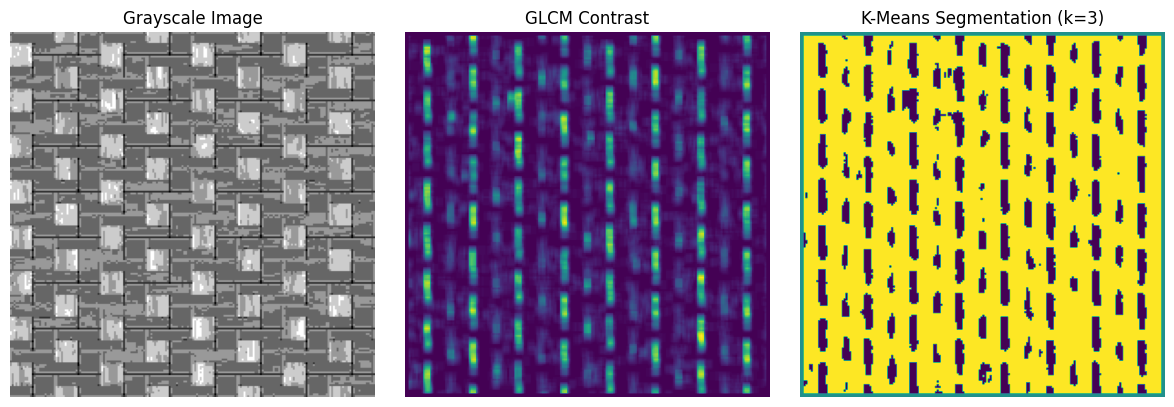

In [15]:
# Load a texture image and convert it to grayscale
img = cv2.imread('texture.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Resize for faster neighbourhood feature extraction
gray = cv2.resize(gray, (200, 200))
gray = (gray / 4).astype(np.uint8)  # Reduce levels from 256 to 64

# Create feature maps for GLCM contrast, energy, and homogeneity
contrast_map = np.zeros(gray.shape, dtype=np.float32)
energy_map = np.zeros(gray.shape, dtype=np.float32)
homogeneity_map = np.zeros(gray.shape, dtype=np.float32)

# Compute GLCM features for each 5×5 neighbourhood
for y in range(2, gray.shape[0] - 2):
    for x in range(2, gray.shape[1] - 2):
        patch = gray[y-2:y+3, x-2:x+3]
        glcm = graycomatrix(patch, distances=[1], angles=[0],
                            levels=64, symmetric=True, normed=True)
        contrast_map[y, x] = graycoprops(glcm, 'contrast')[0, 0]
        energy_map[y, x] = graycoprops(glcm, 'energy')[0, 0]
        homogeneity_map[y, x] = graycoprops(glcm, 'homogeneity')[0, 0]

# Combine the three texture features and cluster pixels into 3 groups

os.environ["LOKY_MAX_CPU_COUNT"] = "4"
features = np.stack([contrast_map.flatten(),
                     energy_map.flatten(),
                     homogeneity_map.flatten()], axis=1)
features = (features - features.mean(axis=0)) / (features.std(axis=0) + 1e-8)
labels = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(features)
segmented = labels.reshape(gray.shape)

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.imshow(gray, cmap='gray')
plt.title('Grayscale Image')
plt.axis('off')
plt.subplot(1, 3, 2)
plt.imshow(contrast_map, cmap='viridis')
plt.title('GLCM Contrast')
plt.axis('off')
plt.subplot(1, 3, 3)
plt.imshow(segmented, cmap='viridis')
plt.title('K-Means Segmentation (k=3)')
plt.axis('off')
plt.tight_layout()
plt.show()



#### Write observations on how feature choice influences segmentation quality.

In [16]:
print("Observation: ")
print("GLCM contrast highlights texture variations, while energy and homogeneity help identify uniform regions. Combining these features improves texture-based segmentation, but similar textures may stillbe grouped together incorrectly.")

Observation: 
GLCM contrast highlights texture variations, while energy and homogeneity help identify uniform regions. Combining these features improves texture-based segmentation, but similar textures may stillbe grouped together incorrectly.


## Problem 6: Multi-Feature Segmentation for Disease Detection

#### Load a plant or skin lesion image. 
#### Construct a feature vector combining:
#### -Intensity
#### -Gradient magnitude (Sobel)
#### -Local texture variance Segment the image using K-means or Mean Shift.

<>:6: SyntaxWarning: invalid escape sequence '\k'
<>:6: SyntaxWarning: invalid escape sequence '\k'
C:\Users\mis\AppData\Local\Temp\ipykernel_19120\3824199490.py:6: SyntaxWarning: invalid escape sequence '\k'
  img = cv2.imread('D:\kush\Assignment 2\clean_gray.jpg')


d:\kush\Assignment 2
False
['city.jpg', 'clean_gray.jpg', 'IPP_Practical-2.ipynb', 'outdoor.jpg', 'smooth_image.jpg', 'texture.jpg']


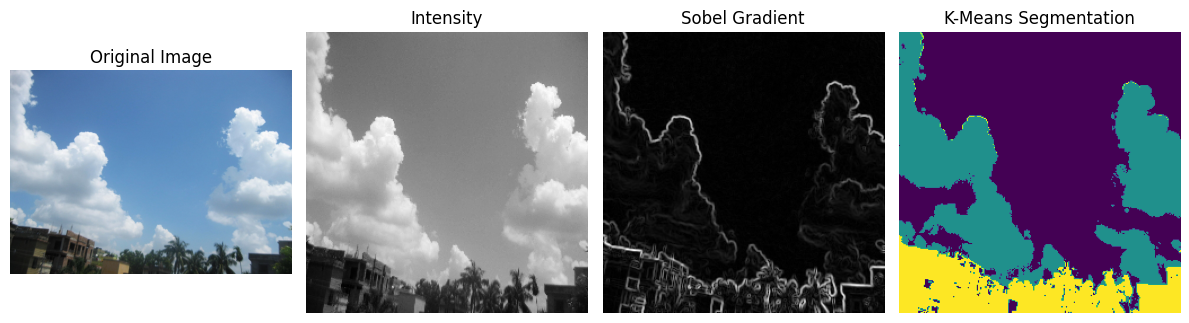

In [20]:
import os
print(os.getcwd())                       # folder Python is searching in
print(os.path.exists('leaf_disease.jpg'))  # True if the file is found
print(os.listdir())                      # files in that folder
# Load plant leaf image and convert it to grayscale
img = cv2.imread('D:\kush\Assignment 2\clean_gray.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
gray = cv2.resize(gray, (250, 250))

# Feature 1: intensity
intensity = gray.astype(np.float32) / 255.0

# Feature 2: Sobel gradient magnitude
sobel_x = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
gradient = cv2.magnitude(sobel_x, sobel_y)
gradient = gradient / (gradient.max() + 1e-8)

# Feature 3: local 3×3 texture variance
gray_float = gray.astype(np.float32)
local_mean = cv2.blur(gray_float, (3, 3))
local_mean_square = cv2.blur(gray_float ** 2, (3, 3))
variance = np.maximum(local_mean_square - local_mean ** 2, 0)
variance = variance / (variance.max() + 1e-8)

# Combine the three features and apply K-means segmentation
features = np.stack([intensity.flatten(), gradient.flatten(), variance.flatten()], axis=1)
labels = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(features)
segmented = labels.reshape(gray.shape)

plt.figure(figsize=(12, 4))
plt.subplot(1, 4, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('off')
plt.subplot(1, 4, 2)
plt.imshow(intensity, cmap='gray')
plt.title('Intensity')
plt.axis('off')
plt.subplot(1, 4, 3)
plt.imshow(gradient, cmap='gray')
plt.title('Sobel Gradient')
plt.axis('off')
plt.subplot(1, 4, 4)
plt.imshow(segmented, cmap='viridis')
plt.title('K-Means Segmentation')
plt.axis('off')
plt.tight_layout()
plt.show()

#### Evaluate:
#### Which feature contributed most to separating diseased vs healthy regions
#### Any misclassifications and why they occurred


In [21]:
print("Evaluation:")
print("- Intensity helps separate dark diseased spots from healthy green regions.")
print("- Sobel gradient highlights leaf boundaries and spot edges.")
print("- Local variance identifies texture differences.")
print("- Misclassifications occur because diseased and healthy regions may have similar intensity or texture, and background pixels may form separate clusters.")

Evaluation:
- Intensity helps separate dark diseased spots from healthy green regions.
- Sobel gradient highlights leaf boundaries and spot edges.
- Local variance identifies texture differences.
- Misclassifications occur because diseased and healthy regions may have similar intensity or texture, and background pixels may form separate clusters.
